In [ ]:
!curl -fL --retry 3 -o /content/digikala-comments.csv "https://huggingface.co/datasets/RadeAI/Digikala_comments_products/resolve/main/digikala-comments.csv"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1022  100  1022    0     0   9288      0 --:--:-- --:--:-- --:--:--  9376
100 1219M  100 1219M    0     0  50.1M      0  0:00:24  0:00:24 --:--:-- 94.4M


In [ ]:
import csv
import math
from collections import Counter
from pathlib import Path

path = Path("/content/digikala-comments.csv")
csv.field_size_limit(10_000_000)

required = {"id", "body", "rate", "recommendation_status", "product_id"}
missing = Counter()
labels = Counter()
seen_ids = set()
records = malformed = duplicate_ids = invalid_rates = out_of_range = 0
min_rate, max_rate = math.inf, -math.inf

with path.open(encoding="utf-8-sig", newline="") as file:
    reader = csv.reader(file, strict=True)
    columns = next(reader)
    absent = required.difference(columns)
    if absent:
        raise ValueError(f"Missing required columns: {sorted(absent)}")

    id_idx, label_idx, rate_idx = map(
        columns.index, ("id", "recommendation_status", "rate")
    )

    for row in reader:
        records += 1
        if len(row) != len(columns):
            malformed += 1
            continue

        for column, value in zip(columns, row):
            if not value.strip():
                missing[column] += 1

        row_id = row[id_idx].strip()
        if row_id:
            duplicate_ids += row_id in seen_ids
            seen_ids.add(row_id)

        label = row[label_idx].strip()
        if label:
            labels[label] += 1

        raw_rate = row[rate_idx].strip()
        if not raw_rate:
            continue
        try:
            rate = float(raw_rate)
        except ValueError:
            invalid_rates += 1
            continue
        if not math.isfinite(rate):
            invalid_rates += 1
            continue

        min_rate, max_rate = min(min_rate, rate), max(max_rate, rate)
        out_of_range += not 0 <= rate <= 5

valid_rows = records - malformed
print(f"Records: {records:,} | Columns: {len(columns)} | Malformed: {malformed:,}")
print(f"Duplicate IDs (extra rows): {duplicate_ids:,}")
print("Observed recommendation values:", dict(labels.most_common()))
print("Numeric rate range:", (min_rate, max_rate) if min_rate != math.inf else None)
print(f"Invalid nonempty rate: {invalid_rates:,} | Outside 0–5: {out_of_range:,}")
print("Blank values in correctly shaped rows:")

for column in columns:
    percentage = 100 * missing[column] / valid_rows if valid_rows else 0
    print(f"  {column}: {missing[column]:,} ({percentage:.2f}%)")

Records: 6,156,289 | Columns: 15 | Malformed: 0
Duplicate IDs (extra rows): 3,229
Observed recommendation values: {'recommended': 4162839, 'nan': 894426, 'no_idea': 594121, 'not_recommended': 504903}
Numeric rate range: (0.0, 2500.0)
Invalid nonempty rate: 0 | Outside 0–5: 1
Blank values in correctly shaped rows:
  id: 0 (0.00%)
  title: 1,353 (0.02%)
  body: 0 (0.00%)
  created_at: 0 (0.00%)
  rate: 0 (0.00%)
  recommendation_status: 0 (0.00%)
  is_buyer: 0 (0.00%)
  product_id: 0 (0.00%)
  advantages: 0 (0.00%)
  disadvantages: 0 (0.00%)
  likes: 0 (0.00%)
  dislikes: 0 (0.00%)
  seller_title: 0 (0.00%)
  seller_code: 0 (0.00%)
  true_to_size_rate: 0 (0.00%)


In [ ]:
import pandas as pd

path = "/content/digikala-comments.csv"
blank_counts = pd.Series(dtype="int64")
nan_counts = pd.Series(dtype="int64")
buyer_parts = []
band_parts = []
total = 0

for chunk in pd.read_csv(path, chunksize=200_000, dtype=str, keep_default_na=False):
    chunk = chunk.apply(lambda column: column.str.strip())
    total += len(chunk)

    blank = chunk.eq("")
    literal_nan = chunk.eq("nan")
    blank_counts = blank_counts.add(blank.sum(), fill_value=0)
    nan_counts = nan_counts.add(literal_nan.sum(), fill_value=0)
    label_missing = blank["recommendation_status"] | literal_nan["recommendation_status"]

    rate = pd.to_numeric(chunk["rate"], errors="coerce")
    band = pd.Series("invalid", index=chunk.index)
    band.loc[rate.between(0, 2.5, inclusive="left")] = "low"
    band.loc[rate.between(2.5, 4, inclusive="left")] = "medium"
    band.loc[rate.between(4, 5, inclusive="both")] = "high"

    buyer = chunk["is_buyer"].replace({"": "missing", "nan": "missing"})
    buyer_parts.append(label_missing.groupby(buyer).agg(rows="size", missing="sum"))
    band_parts.append(label_missing.groupby(band).agg(rows="size", missing="sum"))

missing_by_column = pd.DataFrame({
    "blank": blank_counts.astype(int),
    "literal_nan": nan_counts.astype(int),
    "missing_pct": (100 * (blank_counts + nan_counts) / total).round(2),
})

by_buyer = pd.concat(buyer_parts).groupby(level=0).sum()
by_buyer["missing_pct"] = (100 * by_buyer["missing"] / by_buyer["rows"]).round(2)

by_band = pd.concat(band_parts).groupby(level=0).sum()
by_band["share_pct"] = (100 * by_band["rows"] / total).round(2)
by_band["missing_pct"] = (100 * by_band["missing"] / by_band["rows"]).round(2)

print("1. Missing values by column")
print(missing_by_column.to_string())
print("\n2. Missing recommendation by is_buyer")
print(by_buyer.to_string())
print("\n3. Rating bands and missing recommendation")
print(by_band.to_string())

1. Missing values by column
                       blank  literal_nan  missing_pct
advantages                 0      5448084        88.50
body                       0          637         0.01
created_at                 0            0         0.00
disadvantages              0      5744017        93.30
dislikes                   0            0         0.00
id                         0            0         0.00
is_buyer                   0            0         0.00
likes                      0            0         0.00
product_id                 0            0         0.00
rate                       0            0         0.00
recommendation_status      0       894426        14.53
seller_code                0       302181         4.91
seller_title               0       302181         4.91
title                   1353      2865062        46.56
true_to_size_rate          0      6065516        98.53

2. Missing recommendation by is_buyer
             rows  missing  missing_pct
is_buyer     

In [ ]:
from collections import Counter
from math import ceil

import pandas as pd

path = "/content/digikala-comments.csv"
columns = ["product_id", "seller_code", "is_buyer", "recommendation_status"]
review_counts = Counter()
missing_counts = Counter()
buyer_counts = Counter()
buyer_missing_counts = Counter()
seller_codes = set()

for chunk in pd.read_csv(
    path, usecols=columns, chunksize=200_000, dtype=str, keep_default_na=False
):
    product = chunk["product_id"].str.strip()
    seller = chunk["seller_code"].str.strip()
    buyer = chunk["is_buyer"].str.strip().eq("True")
    missing = chunk["recommendation_status"].str.strip().isin(["", "nan"])

    review_counts.update(product.value_counts().to_dict())
    missing_counts.update(product[missing].value_counts().to_dict())
    buyer_counts.update(product[buyer].value_counts().to_dict())
    buyer_missing_counts.update(product[buyer & missing].value_counts().to_dict())
    seller_codes.update(seller[~seller.isin(["", "nan"])].unique())

products = pd.DataFrame({"reviews": pd.Series(review_counts, dtype="int64")})
for column, counts in [
    ("missing", missing_counts),
    ("buyer_reviews", buyer_counts),
    ("buyer_missing", buyer_missing_counts),
]:
    products[column] = pd.Series(counts, dtype="int64").reindex(
        products.index, fill_value=0
    )

frequency = pd.cut(
    products["reviews"],
    bins=[0, 1, 5, 20, 100, float("inf")],
    labels=["1", "2–5", "6–20", "21–100", "101+"],
)
summary = products.groupby(frequency, observed=True).agg(
    products=("reviews", "size"),
    reviews=("reviews", "sum"),
    missing=("missing", "sum"),
    buyer_reviews=("buyer_reviews", "sum"),
    buyer_missing=("buyer_missing", "sum"),
)
summary["missing_pct"] = (100 * summary["missing"] / summary["reviews"]).round(2)
summary["buyer_missing_pct"] = (
    100 * summary["buyer_missing"] / summary["buyer_reviews"]
).round(2)

top_count = ceil(len(products) * 0.01)
top_reviews = sum(count for _, count in review_counts.most_common(top_count))

print(f"Unique products: {len(products):,}")
print(f"Unique nonmissing seller codes: {len(seller_codes):,}")
print(f"Review share of top 1% products: {top_reviews / products['reviews'].sum():.2%}")
print("\nReviews per product")
print(products["reviews"].describe(percentiles=[.5, .9, .95, .99]).to_string())
print("\nMissing recommendation by reviews per product")
print(summary.to_string())

Unique products: 331,599
Unique nonmissing seller codes: 29,213
Review share of top 1% products: 10.85%

Reviews per product
count    331599.000000
mean         18.565463
std          40.934097
min           1.000000
50%           4.000000
90%          46.000000
95%         110.000000
99%         200.000000
max         400.000000

Missing recommendation by reviews per product
         products  reviews  missing  buyer_reviews  buyer_missing  missing_pct  buyer_missing_pct
reviews                                                                                          
1           91944    91944    18669          81829           8554        20.30              10.45
2–5        106514   322841    61262         294020          32441        18.98              11.03
6–20        73204   788532   135662         734776          81906        17.20              11.15
21–100      42033  1854574   279428        1757496         182350        15.07              10.38
101+        17904  3098398   3994

In [ ]:
import pandas as pd

path = "/content/digikala-comments.csv"
parts = []

for chunk in pd.read_csv(
    path,
    usecols=["body", "rate", "recommendation_status"],
    chunksize=200_000,
    dtype=str,
    keep_default_na=False,
):
    body = chunk["body"].str.strip()
    body = body.mask(body.isin(["", "nan"]))
    recommendation = chunk["recommendation_status"].str.strip().replace(
        {"": "missing", "nan": "missing"}
    )

    parts.append(pd.DataFrame({
        "chars": body.str.len().astype("Int32"),
        "words": body.str.count(r"\S+").astype("Int32"),
        "rate": pd.to_numeric(chunk["rate"], errors="coerce"),
        "recommendation": recommendation.astype("category"),
    }))

profile = pd.concat(parts, ignore_index=True)
del parts

raw = profile["rate"].dropna()
valid = raw[raw.between(0, 5)]
percentiles = [.05, .25, .50, .75, .90, .95, .99]

rate_stats = pd.DataFrame({
    "raw": raw.describe(percentiles=percentiles),
    "valid_0_to_5": valid.describe(percentiles=percentiles),
})
rate_stats.loc["unique"] = [raw.nunique(), valid.nunique()]
rate_stats.loc["fractional_pct"] = [
    100 * raw.mod(1).ne(0).mean(),
    100 * valid.mod(1).ne(0).mean(),
]

profile["band"] = pd.cut(
    profile["rate"].where(profile["rate"].between(0, 5)),
    bins=[0, 2.5, 4, float("inf")],
    labels=["low", "medium", "high"],
    right=False,
)

print("1. Numeric rating statistics")
print(rate_stats.round(4).to_string())
print("\n2. Valid ratings by recommendation status")
print(profile.loc[valid.index].groupby("recommendation", observed=True)["rate"]
      .agg(["size", "mean", "median"]).round(3).to_string())

lengths = profile[["chars", "words"]].dropna()
print("\n3. Text length (nonmissing bodies)")
print(lengths.describe(percentiles=[.50, .90, .95, .99]).round(2).to_string())
for name, mask in [
    ("Short (at most 3 words)", lengths["words"].le(3)),
    ("Long (at least 100 words)", lengths["words"].ge(100)),
]:
    print(f"{name}: {mask.sum():,} ({mask.mean():.2%})")

for target in ["recommendation", "band"]:
    print(f"\n4. Median and 95th-percentile length by {target}")
    summary = profile.groupby(target, observed=True)[["chars", "words"]]
    print(summary.quantile([.50, .95]).unstack().round(1).to_string())

1. Numeric rating statistics
                         raw  valid_0_to_5
count           6.156289e+06  6.156288e+06
mean            3.648300e+00  3.647900e+00
std             1.861900e+00  1.566600e+00
min             0.000000e+00  0.000000e+00
5%              0.000000e+00  0.000000e+00
25%             3.000000e+00  3.000000e+00
50%             4.000000e+00  4.000000e+00
75%             5.000000e+00  5.000000e+00
90%             5.000000e+00  5.000000e+00
95%             5.000000e+00  5.000000e+00
99%             5.000000e+00  5.000000e+00
max             2.500000e+03  5.000000e+00
unique          1.780000e+02  1.770000e+02
fractional_pct  3.705600e+00  3.705600e+00

2. Valid ratings by recommendation status
                    size   mean  median
recommendation                         
missing           894426  4.041     4.0
no_idea           594121  2.923     3.0
not_recommended   504903  1.448     1.0
recommended      4162838  3.934     4.0

3. Text length (nonmissing bodies)
       

In [ ]:
%pip -q install duckdb

import duckdb

with duckdb.connect(config={"memory_limit": "3GB", "threads": "2"}) as db:
    db.execute("""
        CREATE TEMP TABLE reviews AS
        SELECT
            trim(id) AS review_id,
            trim(product_id) AS product_id,
            CASE WHEN trim(body) NOT IN ('', 'nan') THEN body END AS body,
            CASE trim(recommendation_status)
                WHEN 'recommended' THEN 0
                WHEN 'not_recommended' THEN 1
                WHEN 'no_idea' THEN 2
            END AS recommendation,
            TRY_CAST(rate AS DOUBLE) AS rate
        FROM read_csv('/content/digikala-comments.csv', header = true, all_varchar = true)
    """)

    rows = db.execute("SELECT count(*) FROM reviews").fetchone()[0]
    if rows != 6_156_289:
        raise ValueError(f"Unexpected record count: {rows:,}")

    id_summary = db.execute("""
        WITH repeated AS (
            SELECT review_id
            FROM reviews
            GROUP BY review_id
            HAVING count(*) > 1
        ), variants AS (
            SELECT
                review_id,
                count(*) AS n,
                count(DISTINCT row(product_id, body, recommendation, rate)) AS versions,
                count(DISTINCT product_id) AS products
            FROM reviews SEMI JOIN repeated USING (review_id)
            GROUP BY review_id
        )
        SELECT
            count(*) AS repeated_ids,
            sum(n - 1)::BIGINT AS extra_rows,
            count(*) FILTER (WHERE versions = 1) AS ids_with_same_model_fields,
            count(*) FILTER (WHERE versions > 1) AS ids_with_different_model_fields,
            count(*) FILTER (WHERE products > 1) AS ids_across_products
        FROM variants
    """).df()

    body_summary = db.execute("""
        WITH labeled AS (
            SELECT
                body, product_id, recommendation,
                CASE
                    WHEN rate >= 0 AND rate < 2.5 THEN 0
                    WHEN rate >= 2.5 AND rate < 4 THEN 1
                    WHEN rate BETWEEN 4 AND 5 THEN 2
                END AS rating_band
            FROM reviews
            WHERE body IS NOT NULL
        ), repeated AS (
            SELECT
                count(*) AS n,
                min(product_id) <> max(product_id) AS across_products,
                min(recommendation) <> max(recommendation) AS recommendation_conflict,
                min(rating_band) <> max(rating_band) AS band_conflict
            FROM labeled
            GROUP BY body
            HAVING count(*) > 1
        )
        SELECT
            count(*) AS repeated_texts,
            sum(n)::BIGINT AS rows_with_repeated_text,
            sum(n - 1)::BIGINT AS extra_rows,
            count(*) FILTER (WHERE across_products) AS texts_across_products,
            count(*) FILTER (WHERE recommendation_conflict) AS texts_with_recommendation_conflict,
            count(*) FILTER (WHERE band_conflict) AS texts_with_rating_band_conflict
        FROM repeated
    """).df()

print("1. Duplicate review IDs")
print(id_summary.T.to_string(header=False))
print("\n2. Exact repeated review texts")
print(body_summary.T.to_string(header=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

1. Duplicate review IDs
repeated_ids                     3226
extra_rows                       3229
ids_with_same_model_fields       2911
ids_with_different_model_fields   315
ids_across_products                 0

2. Exact repeated review texts
repeated_texts                       197744
rows_with_repeated_text             2217139
extra_rows                          2019395
texts_across_products                195210
texts_with_recommendation_conflict    31941
texts_with_rating_band_conflict       82619


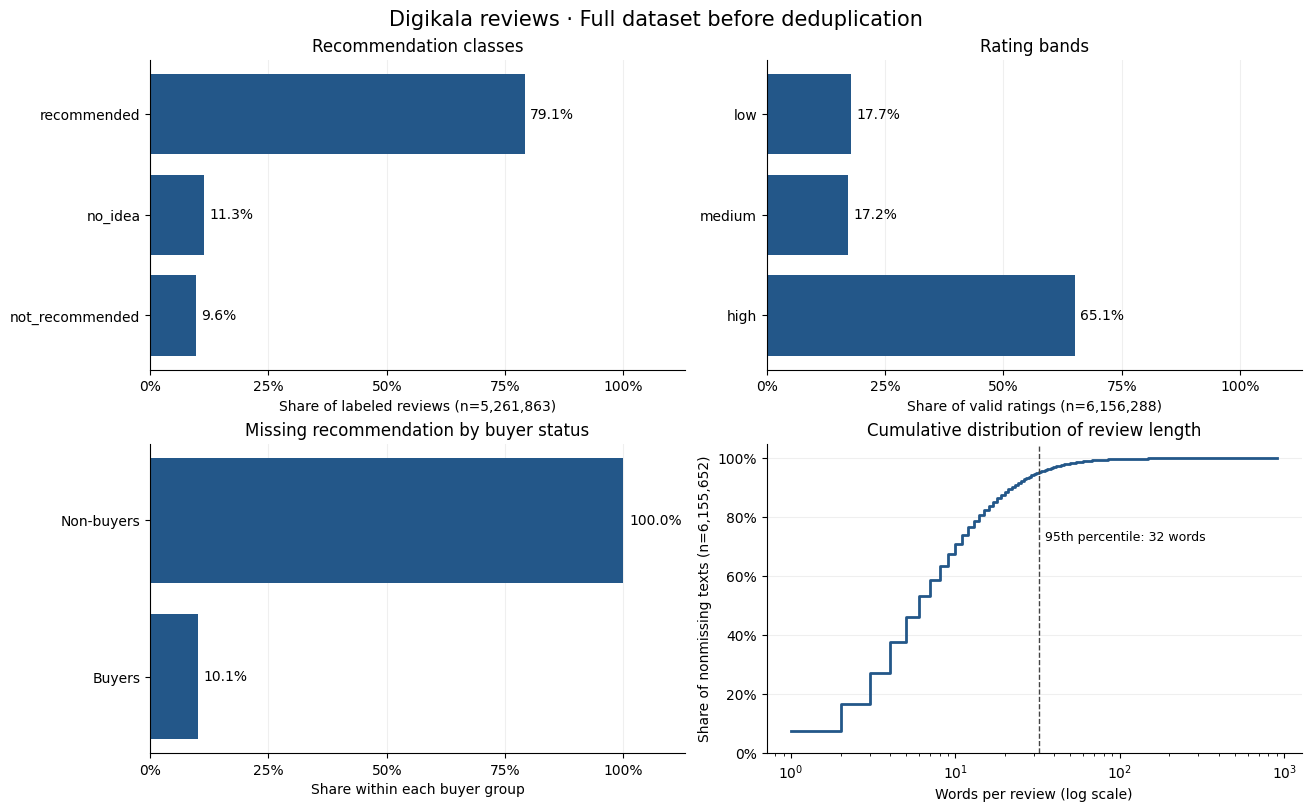

1. Class imbalance: 79.11% of labeled reviews recommend purchase; 65.05% of valid ratings are high. Report macro F1.
2. Missing labels: 100.00% for non-buyers and 10.12% for buyers. Keep the fixed artificial masking protocol for the main experiment.
3. Text length: Median 6 words; 95th percentile 32 words. Measure tokenizer lengths before choosing max_length.
4. Product concentration: The top 1% of products account for 10.85% of reviews. Split by product and measure exact-text overlap across splits.
5. Duplicate IDs: 315 repeated IDs differ in model fields. Inspect these differences before selecting a deduplication rule.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

recommendation_counts = pd.Series({
    name: labels[name]
    for name in ["recommended", "no_idea", "not_recommended"]
})
rating_counts = by_band.loc[["low", "medium", "high"], "rows"]
buyer_stats = by_buyer.loc[["False", "True"]]
buyer_missing = (100 * buyer_stats["missing"] / buyer_stats["rows"]).rename(
    index={"False": "Non-buyers", "True": "Buyers"}
)
word_counts = profile["words"].dropna()
word_frequency = word_counts.value_counts().sort_index()
word_cdf = 100 * word_frequency.cumsum() / word_frequency.sum()
word_p95 = word_counts.quantile(.95)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
fig.suptitle("Digikala reviews · Full dataset before deduplication", fontsize=15)

def plot_percentages(ax, percentages, title, xlabel):
    bars = ax.barh(percentages.index, percentages.to_numpy(), color="#235789")
    ax.invert_yaxis()
    ax.set(title=title, xlabel=xlabel, xlim=(0, 113))
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.bar_label(bars, labels=[f"{value:.1f}%" for value in percentages], padding=4)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=.2)

recommendation_share = 100 * recommendation_counts / recommendation_counts.sum()
rating_share = 100 * rating_counts / rating_counts.sum()

plot_percentages(
    axes[0, 0], recommendation_share,
    "Recommendation classes", f"Share of labeled reviews (n={recommendation_counts.sum():,})",
)
plot_percentages(
    axes[0, 1], rating_share,
    "Rating bands", f"Share of valid ratings (n={rating_counts.sum():,})",
)
plot_percentages(
    axes[1, 0], buyer_missing,
    "Missing recommendation by buyer status", "Share within each buyer group",
)

ax = axes[1, 1]
ax.step(word_frequency.index.to_numpy(dtype=int), word_cdf.to_numpy(),
        where="post", color="#235789", linewidth=2)
ax.axvline(word_p95, color="#444444", linestyle="--", linewidth=1)
ax.annotate(f"95th percentile: {word_p95:g} words", xy=(word_p95, 72),
            xytext=(5, 0), textcoords="offset points", fontsize=9)
ax.set(
    title="Cumulative distribution of review length",
    xlabel="Words per review (log scale)",
    ylabel=f"Share of nonmissing texts (n={len(word_counts):,})",
    xscale="log", ylim=(0, 105),
)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.grid(axis="y", alpha=.2)

for ax in axes.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.show()

print("1. Class imbalance:",
      f"{recommendation_share['recommended']:.2f}% of labeled reviews recommend purchase;",
      f"{rating_share['high']:.2f}% of valid ratings are high. Report macro F1.")
print("2. Missing labels:",
      f"{buyer_missing['Non-buyers']:.2f}% for non-buyers and {buyer_missing['Buyers']:.2f}% for buyers.",
      "Keep the fixed artificial masking protocol for the main experiment.")
print("3. Text length:",
      f"Median {word_counts.median():g} words; 95th percentile {word_p95:g} words.",
      "Measure tokenizer lengths before choosing max_length.")
print("4. Product concentration:",
      f"The top 1% of products account for {top_reviews / products['reviews'].sum():.2%} of reviews.",
      "Split by product and measure exact-text overlap across splits.")
print("5. Duplicate IDs:",
      f"{id_summary.at[0, 'ids_with_different_model_fields']:,} repeated IDs differ in model fields.",
      "Inspect these differences before selecting a deduplication rule.")

In [ ]:
import duckdb

with duckdb.connect(config={"memory_limit": "3GB", "threads": "2"}) as db:
    duplicate_details = db.execute("""
        WITH reviews AS MATERIALIZED (
            SELECT
                trim(id) AS review_id,
                CASE WHEN trim(body) NOT IN ('', 'nan') THEN body END AS body,
                CASE WHEN trim(recommendation_status) IN
                    ('recommended', 'not_recommended', 'no_idea')
                    THEN trim(recommendation_status)
                END AS recommendation,
                TRY_CAST(rate AS DOUBLE) AS rate
            FROM read_csv('/content/digikala-comments.csv', header = true, all_varchar = true)
        ), repeated AS (
            SELECT review_id
            FROM reviews
            GROUP BY review_id
            HAVING count(*) > 1
        ), variants AS (
            SELECT
                review_id, body, recommendation, rate,
                CASE
                    WHEN rate >= 0 AND rate < 2.5 THEN 0
                    WHEN rate >= 2.5 AND rate < 4 THEN 1
                    WHEN rate BETWEEN 4 AND 5 THEN 2
                END AS rating_band
            FROM reviews SEMI JOIN repeated USING (review_id)
        ), per_id AS (
            SELECT
                count(*) AS rows_per_id,
                count(body) AS bodies_present,
                count(recommendation) AS recommendations_present,
                count(rating_band) AS bands_present,
                count(DISTINCT body) AS texts,
                count(DISTINCT recommendation) AS recommendation_classes,
                count(DISTINCT rate) AS numeric_rates,
                count(DISTINCT rating_band) AS rating_bands
            FROM variants
            GROUP BY review_id
        )
        SELECT
            count(*) AS repeated_ids,
            count(*) FILTER (WHERE texts > 1) AS different_nonmissing_texts,
            count(*) FILTER (WHERE bodies_present BETWEEN 1 AND rows_per_id - 1)
                AS both_present_and_missing_text,
            count(*) FILTER (WHERE recommendation_classes > 1)
                AS conflicting_recommendation_classes,
            count(*) FILTER (WHERE recommendations_present BETWEEN 1 AND rows_per_id - 1)
                AS both_labeled_and_unlabeled_recommendation,
            count(*) FILTER (WHERE numeric_rates > 1) AS different_numeric_rates,
            count(*) FILTER (WHERE numeric_rates > 1 AND rating_bands = 1
                             AND bands_present = rows_per_id) AS different_rates_same_valid_band,
            count(*) FILTER (WHERE rating_bands > 1) AS conflicting_rating_bands,
            count(*) FILTER (WHERE bands_present BETWEEN 1 AND rows_per_id - 1)
                AS both_valid_and_invalid_rating
        FROM per_id
    """).df()

print(duplicate_details.T.to_string(header=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

repeated_ids                               3226
different_nonmissing_texts                  241
both_present_and_missing_text                 0
conflicting_recommendation_classes           43
both_labeled_and_unlabeled_recommendation    58
different_numeric_rates                      79
different_rates_same_valid_band              31
conflicting_rating_bands                     48
both_valid_and_invalid_rating                 0


In [ ]:
import duckdb

with duckdb.connect(
    "/content/digikala_project.duckdb",
    config={"memory_limit": "3GB", "threads": "2"},
) as db:
    db.execute("""
        CREATE TEMP TABLE source_reviews AS
        WITH parsed AS (
            SELECT
                trim(id) AS id,
                trim(product_id) AS product_id,
                CASE WHEN trim(body) NOT IN ('', 'nan') THEN body END AS body,
                nullif(nullif(trim(recommendation_status), ''), 'nan')
                    AS recommendation_status,
                try_cast(rate AS DOUBLE) AS rate
            FROM read_csv(
                '/content/digikala-comments.csv',
                header = true,
                all_varchar = true
            )
        )
        SELECT id, product_id, body, recommendation_status,
            CASE
                WHEN rate >= 0 AND rate < 2.5 THEN 'low'
                WHEN rate >= 2.5 AND rate < 4 THEN 'medium'
                WHEN rate BETWEEN 4 AND 5 THEN 'high'
            END AS rating_band
        FROM parsed
    """)

    db.execute("""
        CREATE TEMP TABLE repeated_ids AS
        SELECT id FROM source_reviews GROUP BY id HAVING count(*) > 1
    """)

    db.execute("""
        CREATE TEMP TABLE duplicate_groups AS
        SELECT id,
            min(product_id) AS product_id,
            min(body) AS body,
            min(recommendation_status) AS recommendation_status,
            min(rating_band) AS rating_band,
            count(DISTINCT product_id) AS product_versions,
            count(DISTINCT body) AS text_versions,
            count(DISTINCT recommendation_status) AS recommendation_versions,
            count(DISTINCT rating_band) AS band_versions
        FROM source_reviews SEMI JOIN repeated_ids USING (id)
        GROUP BY id
    """)

    db.execute("""
        CREATE OR REPLACE TABLE clean_reviews AS
        SELECT id, product_id, body, recommendation_status, rating_band,
            recommendation_status IS NULL AS naturally_unlabeled
        FROM source_reviews ANTI JOIN repeated_ids USING (id)
        WHERE body IS NOT NULL

        UNION ALL

        SELECT id, product_id, body,
            CASE WHEN recommendation_versions = 1 THEN recommendation_status END,
            CASE WHEN band_versions = 1 THEN rating_band END,
            recommendation_versions = 0 AS naturally_unlabeled
        FROM duplicate_groups
        WHERE text_versions = 1 AND product_versions = 1
    """)

    duplicate_audit = db.execute("""
        SELECT
            count(*) FILTER (WHERE text_versions > 1) AS excluded_ids_multiple_texts,
            count(*) FILTER (WHERE text_versions = 0) AS excluded_repeated_ids_no_text,
            count(*) FILTER (WHERE product_versions <> 1) AS repeated_ids_product_issue,
            count(*) FILTER (WHERE text_versions = 1 AND product_versions = 1
                             AND recommendation_versions > 1) AS merged_ids_rec_masked,
            count(*) FILTER (WHERE text_versions = 1 AND product_versions = 1
                             AND band_versions > 1) AS merged_ids_band_masked
        FROM duplicate_groups
    """).df()

    clean_audit = db.execute("""
        SELECT
            count(*) AS clean_rows,
            count(*) - count(DISTINCT id) AS duplicate_ids_remaining,
            count(*) FILTER (WHERE body IS NULL) AS missing_bodies_remaining,
            count(recommendation_status) AS valid_recommendations,
            count(rating_band) AS valid_rating_bands,
            count(*) FILTER (WHERE naturally_unlabeled) AS naturally_unlabeled_rows,
            count(*) FILTER (WHERE recommendation_status IS NULL
                             AND rating_band IS NULL) AS rows_without_either_target
        FROM clean_reviews
    """).df()

assert clean_audit.at[0, "duplicate_ids_remaining"] == 0
assert clean_audit.at[0, "missing_bodies_remaining"] == 0

print("Deduplication decisions")
print(duplicate_audit.T.to_string(header=False))
print("\nClean review counts")
print(clean_audit.T.to_string(header=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Deduplication decisions
excluded_ids_multiple_texts    241
excluded_repeated_ids_no_text    0
repeated_ids_product_issue       0
merged_ids_rec_masked           16
merged_ids_band_masked          15

Clean review counts
clean_rows                  6152182
duplicate_ids_remaining           0
missing_bodies_remaining          0
valid_recommendations       5258257
valid_rating_bands          6152166
naturally_unlabeled_rows     893909
rows_without_either_target        5


In [ ]:
from hashlib import sha256

import duckdb
import pandas as pd

SPLIT_SEED = 2026
split_order = ["train", "validation", "test"]

def assign_split(product_id):
    key = f"{SPLIT_SEED}|{product_id}".encode("utf-8")
    bucket = int(sha256(key).hexdigest()[:16], 16) % 10_000
    if bucket < 7_000:
        return "train"
    if bucket < 8_500:
        return "validation"
    return "test"

with duckdb.connect(
    "/content/digikala_project.duckdb",
    config={"memory_limit": "3GB", "threads": "2"},
) as db:
    assignments = db.execute(
        "SELECT DISTINCT product_id FROM clean_reviews"
    ).df()
    assignments["split_name"] = assignments["product_id"].map(assign_split)

    db.register("assignments", assignments)
    db.execute("CREATE OR REPLACE TABLE product_split AS SELECT * FROM assignments")

    counts = db.execute("""
        SELECT p.split_name, r.recommendation_status, r.rating_band, count(*) AS n
        FROM clean_reviews r
        JOIN product_split p USING (product_id)
        GROUP BY p.split_name, r.recommendation_status, r.rating_band
    """).df()

    clean_count = db.execute("SELECT count(*) FROM clean_reviews").fetchone()[0]
    assert assignments["product_id"].is_unique
    assert counts["n"].sum() == clean_count

    overlap = db.execute("""
        WITH by_text AS (
            SELECT r.body,
                count(*) FILTER (WHERE p.split_name = 'train') AS train_rows,
                count(*) FILTER (WHERE p.split_name = 'validation') AS val_rows,
                count(*) FILTER (WHERE p.split_name = 'test') AS test_rows
            FROM clean_reviews r
            JOIN product_split p USING (product_id)
            GROUP BY r.body
        )
        SELECT
            count(*) FILTER (WHERE train_rows > 0 AND val_rows > 0)
                AS texts_shared_train_validation,
            count(*) FILTER (WHERE train_rows > 0 AND test_rows > 0)
                AS texts_shared_train_test,
            count(*) FILTER (WHERE val_rows > 0 AND test_rows > 0)
                AS texts_shared_validation_test,
            coalesce(sum(val_rows) FILTER (WHERE train_rows > 0), 0)::BIGINT
                AS validation_rows_with_text_in_train,
            coalesce(sum(test_rows) FILTER (WHERE train_rows > 0), 0)::BIGINT
                AS test_rows_with_text_in_train
        FROM by_text
    """).df()

summary = pd.DataFrame({
    "products": assignments["split_name"].value_counts(),
    "reviews": counts.groupby("split_name")["n"].sum(),
}).reindex(split_order)
summary["review_pct"] = (100 * summary["reviews"] / clean_count).round(2)

print("1. Product-grouped split")
print(summary.to_string())

for target in ["recommendation_status", "rating_band"]:
    distribution = (
        counts.dropna(subset=[target])
        .pivot_table(index="split_name", columns=target, values="n",
                     aggfunc="sum", fill_value=0)
        .reindex(split_order)
    )
    shares = distribution.div(distribution.sum(axis=1), axis=0) * 100
    print(f"\n2. {target} (% among valid labels within each split)")
    print(shares.round(2).to_string())

print("\n3. Exact raw-text overlap")
print(overlap.T.to_string(header=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

1. Product-grouped split
            products  reviews  review_pct
split_name                               
train         231819  4307310       70.01
validation     50031   925197       15.04
test           49742   919675       14.95

2. recommendation_status (% among valid labels within each split)
recommendation_status  no_idea  not_recommended  recommended
split_name                                                  
train                    11.30             9.61        79.08
validation               11.30             9.62        79.08
test                     11.21             9.48        79.31

2. rating_band (% among valid labels within each split)
rating_band   high    low  medium
split_name                       
train        64.99  17.81   17.20
validation   65.03  17.68   17.29
test         65.37  17.51   17.13

3. Exact raw-text overlap
texts_shared_train_validation        77642
texts_shared_train_test              77913
texts_shared_validation_test         40618
validation

In [ ]:
import csv
import json
from pathlib import Path

import duckdb

MASK_SEED = "digikala-semi-supervised-v1"
MASK_RATE = 0.20
output_dir = Path("/content/digikala_splits")
output_dir.mkdir(exist_ok=True)
target_columns = "id, body, recommendation_status, rating_band"

with duckdb.connect(
    "/content/digikala_project.duckdb",
    config={"memory_limit": "3GB", "threads": "2"},
) as db:
    db.execute("""
        CREATE TEMP VIEW assigned_reviews AS
        SELECT r.*, p.split_name
        FROM clean_reviews r JOIN product_split p USING (product_id)
    """)

    db.execute(f"""
        CREATE OR REPLACE TABLE masked_train_ids AS
        WITH ranked AS (
            SELECT id,
                count(*) OVER (PARTITION BY recommendation_status) AS class_count,
                row_number() OVER (
                    PARTITION BY recommendation_status
                    ORDER BY substr(sha256('{MASK_SEED}|' || id), 1, 16), id
                ) AS position
            FROM assigned_reviews
            WHERE split_name = 'train' AND recommendation_status IS NOT NULL
        )
        SELECT id FROM ranked WHERE position <= floor(class_count * {MASK_RATE:.2f})
    """)

    mask_counts = db.execute("""
        SELECT r.recommendation_status AS label,
               count(*) AS labeled_train, count(m.id) AS masked
        FROM assigned_reviews r LEFT JOIN masked_train_ids m USING (id)
        WHERE r.split_name = 'train' AND r.recommendation_status IS NOT NULL
        GROUP BY r.recommendation_status ORDER BY r.recommendation_status
    """).fetchall()
    assert all(masked == labeled // 5 for _, labeled, masked in mask_counts)

    split_counts = dict(db.execute("""
        SELECT split_name, count(*) FROM assigned_reviews GROUP BY split_name
    """).fetchall())

    exports = {
        "train_supervised.csv": f"""
            SELECT {target_columns} FROM assigned_reviews
            ANTI JOIN masked_train_ids USING (id)
            WHERE split_name = 'train'
              AND (recommendation_status IS NOT NULL OR rating_band IS NOT NULL)
        """,
        "train_pseudo_unlabeled.csv": """
            SELECT id, body FROM assigned_reviews
            SEMI JOIN masked_train_ids USING (id)
        """,
        "natural_unlabeled.csv": """
            SELECT id, body FROM assigned_reviews
            WHERE split_name = 'train' AND naturally_unlabeled
        """,
        "validation.csv": f"""
            SELECT {target_columns} FROM assigned_reviews WHERE split_name = 'validation'
        """,
        "test.csv": f"""
            SELECT {target_columns} FROM assigned_reviews WHERE split_name = 'test'
        """,
    }

    file_counts = {}
    for name, query in exports.items():
        destination = output_dir / name
        db.sql(f"{query} ORDER BY id").to_csv(
            str(destination), header=True, overwrite=True, use_tmp_file=True
        )
        file_counts[name] = db.execute(
            "SELECT count(*) FROM read_csv(?, header=true, all_varchar=true)",
            [str(destination)],
        ).fetchone()[0]

        expected = (
            ["id", "body"] if name.endswith("unlabeled.csv")
            else target_columns.split(", ")
        )
        with destination.open(encoding="utf-8", newline="") as file:
            assert next(csv.reader(file)) == expected, name

assert file_counts["train_pseudo_unlabeled.csv"] == sum(row[2] for row in mask_counts)
assert file_counts["validation.csv"] == split_counts["validation"]
assert file_counts["test.csv"] == split_counts["test"]

manifest = {
    "split_seed": 2026,
    "split_strategy": {
        "group_by": "product_id",
        "bucket": "int(sha256('2026|' + product_id)[:16], 16) % 10000",
        "train": "0–6999", "validation": "7000–8499", "test": "8500–9999",
    },
    "mask_seed": MASK_SEED,
    "mask_rate": MASK_RATE,
    "mask_strategy": "Per labeled train class, sort by SHA-256 prefix then id; take floor(0.20 * class_count).",
    "masked_per_class": {
        label: {"labeled_train": labeled, "masked": masked}
        for label, labeled, masked in mask_counts
    },
    "rating_bands": {
        "low": {"interval": "[0, 2.5)", "encoding": 0},
        "medium": {"interval": "[2.5, 4)", "encoding": 1},
        "high": {"interval": "[4, 5]", "encoding": 2},
    },
    "split_rows_before_masking": split_counts,
    "exported_file_rows": file_counts,
    "exact_raw_text_overlap_before_masking": {
        key: int(value) for key, value in overlap.iloc[0].items()
    },
}

(output_dir / "split_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Masking by recommendation class")
for label, labeled, masked in mask_counts:
    print(f"{label:16s} labeled train={labeled:,}  masked={masked:,}")

print("\nExported rows")
for name, count in file_counts.items():
    print(f"{name:30s} {count:,}")
print(f"\nManifest: {output_dir / 'split_manifest.json'}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Masking by recommendation class
no_idea          labeled train=416,318  masked=83,263
not_recommended  labeled train=354,034  masked=70,806
recommended      labeled train=2,912,359  masked=582,471

Exported rows
train_supervised.csv           3,570,765
train_pseudo_unlabeled.csv     736,540
natural_unlabeled.csv          624,586
validation.csv                 925,197
test.csv                       919,675

Manifest: /content/digikala_splits/split_manifest.json


In [ ]:
%%writefile /content/normalize_persian.py

import re
import unicodedata
from html import unescape

_TRANSLATION = str.maketrans({
    "\u064a": "\u06cc",  # Arabic yeh to Persian yeh
    "\u0643": "\u06a9",  # Arabic kaf to Persian kaf
    "\u200b": " ",      # Zero-width space
    "\ufeff": None,
    "\u061c": None,
    "\u200e": None,
    "\u200f": None,
})
_HTML = re.compile(r"<!--.*?-->|</?[A-Za-z][^<>]*>", re.DOTALL)
_URL = re.compile(
    r"(?:https?://|www\.)[A-Za-z0-9._~:/?#\[\]@!$&'()*+,;=%-]+",
    re.IGNORECASE | re.ASCII,
)
_REPEATED_ZWNJ = re.compile("\u200c{2,}")

def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFC", unescape(text)).translate(_TRANSLATION)
    text = _HTML.sub(" ", text)
    text = _URL.sub(" [URL] ", text)
    text = _REPEATED_ZWNJ.sub("\u200c", text)
    return " ".join(text.split()).strip(" \u200c")

if __name__ == "__main__":
    cases = [
        ("كيفيت كالا خوب نيست", "کیفیت کالا خوب نیست"),
        ("  نمی\u200cخرم   ۱۲۳ 👩‍💻  ", "نمی\u200cخرم ۱۲۳ 👩‍💻"),
        ("خوب\u200bبود &lt;br&gt; ولی گران بود", "خوب بود ولی گران بود"),
        ("لینک https://example.com/p/123 😡", "لینک [URL] 😡"),
    ]

    for original, expected in cases:
        result = normalize_text(original)
        assert result == expected, (original, result, expected)
        print(result)

    print(f"{len(cases)} normalization checks passed.")

Writing /content/normalize_persian.py


In [ ]:
!python /content/normalize_persian.py

کیفیت کالا خوب نیست
نمی‌خرم ۱۲۳ 👩‍💻
خوب بود ولی گران بود
لینک [URL] 😡
4 normalization checks passed.


In [ ]:
from pathlib import Path
import shutil
import tarfile

from google.colab import drive

drive.mount("/content/drive")

project_drive = Path("/content/drive/MyDrive/digikala-project-3")
project_drive.mkdir(exist_ok=True)
bundle = Path("/content/digikala_inputs.tar.gz")

with tarfile.open(bundle, "w:gz", compresslevel=3) as archive:
    for name in ["digikala_splits", "normalize_persian.py"]:
        archive.add(Path("/content") / name, arcname=name)

shutil.copyfile(bundle, project_drive / bundle.name)
shutil.copyfile(
    "/content/digikala_project.duckdb",
    project_drive / "digikala_project.duckdb",
)
print("Split files, normalizer, and audit database saved to Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Split files, normalizer, and audit database saved to Google Drive.
